<a href="https://colab.research.google.com/github/CarlosGer7/MetodosNum/blob/main/Metodo_de_Newton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Implementación del Método de Newton
# Leon Espinoza Carlos Germain
## 1. Formulación del Problema y del Método

El **Método de Newton** (o de Newton-Raphson) es una técnica numérica eficiente para encontrar aproximaciones de las raíces de una función real. Se basa en los polinomios de Taylor. Si suponemos que $f \in C^2[a, b]$ y que $p_0 \in [a, b]$ es una aproximación inicial para la raíz $p$, tal que $f'(p_0) \neq 0$ y la diferencia $|p - p_0|$ es "pequeña", el método genera una sucesión $\{p_n\}_{n=0}^{\infty}$ definida por:

$$p_n = p_{n-1} - \frac{f(p_{n-1})}{f'(p_{n-1})} \quad \text{para } n \geq 1$$

###  (Ejemplo de la pág. 50)
Para encontrar una solución a $f(x) = 0$ dada una aproximación inicial $p_0$:
- **Entrada:** Aproximación inicial $p_0$; tolerancia $TOL$; cantidad máxima de iteraciones $N_0$.
- **Salida:** Solución aproximada $p$ o mensaje de falla.

**Paso 1:** Tomar $i = 1$.
**Paso 2:** Mientras $i \leq N_0$ seguir Pasos 3 a 6.
**Paso 3:** Calcular $p = p_0 - f(p_0)/f'(p_0)$.
**Paso 4:** Si $|p - p_0| < TOL$ entonces **SALIDA** ($p$); (El procedimiento fue exitoso); **PARAR**.
**Paso 5:** Tomar $i = i + 1$.
**Paso 6:** Tomar $p_0 = p$. (Actualizar $p_0$).
**Paso 7:** **SALIDA** ('El método falló'); **PARAR**.

## 2. Solucion

Se resolverá el **Ejemplo 1 **:
Considere la función $f(x) = \cos x - x = 0$. Aproxime una raíz de $f$ usando el método de Newton.

Para aplicar el método, necesitamos la derivada de la función:
$$f'(x) = -\sin x - 1$$

Iniciaremos con el valor $p_0 = \pi / 4$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sympy as sp

%matplotlib inline

# Definición de símbolos para encontrar la derivada


In [ ]:
x_sym = sp.symbols('x')
funcion_sym = sp.cos(x_sym) - x_sym
derivada_sym = sp.diff(funcion_sym, x_sym)

print("Función f(x):", funcion_sym)
print("Derivada f'(x):", derivada_sym)


Función f(x): -x + cos(x)
Derivada f'(x): -sin(x) - 1


# Definición de las funciones evaluables

In [ ]:
def f(x):
    """Retorna f(x) = cos(x) - x"""
    return np.cos(x) - x

def df(x):
    """Retorna la derivada f'(x) = -sin(x) - 1"""
    return -np.sin(x) - 1

## 3. Implementación del Método de Newton-Raphson

Se implementa el código guardando las iteraciones en listas (`lista`, `error`) para posteriormente crear un `DataFrame` con la librería `pandas`, tal como se plantea en la estructura vista en clase, pero añadiendo el criterio de tolerancia (TOL) del libro.


In [ ]:
def newton(p0, n_max, tol=1e-9):
    """
    Algoritmo de Newton-Raphson estructurado con almacenamiento de listas.
    """
    lista = []
    error = []

    lista.append(p0)
    error.append(np.nan)


    for i in range(1, n_max + 1):
        fp0 = f(p0)
        dif = df(p0)


        if dif == 0:
            print("El método falló: derivada cero.")
            break


        p = p0 - (fp0 / dif)
        lista.append(p)


        e = np.abs(p - p0)
        error.append(e)


        if e < tol:
            print(f" Convergencia en {i} iteraciones.")
            break


        p0 = p

    else:

        print(f" El método falló después de {n_max} iteraciones.")

    return lista, error



## 4. Ejecución y Tabla de Resultados

In [ ]:
p_inicial = np.pi / 4
iteraciones_max = 10
tolerancia = 1e-9


p_vals, e_vals = newton(p_inicial, iteraciones_max, tolerancia)


tabla_resultados = pd.DataFrame({
    'p_n (Aproximación)': p_vals,
    'Error Absoluto |p_n - p_{n-1}|': e_vals
})


tabla_resultados.index.name = 'n'


solucion_final = p_vals[-1]
print(f"\n LA SOLUCIÓN FINAL APROXIMADA ES: p = {solucion_final:.10f}\n")

# Mostramos la tabla
tabla_resultados

 Convergencia en 4 iteraciones.

 LA SOLUCIÓN FINAL APROXIMADA ES: p = 0.7390851332



,p_n (Aproximación),Error Absoluto |p_n - p_{n-1}|
n,,
0,0.785398,NaN
1,0.739536,4.586203e-02
2,0.739085,4.509554e-04
3,0.739085,4.489085e-08
4,0.739085,4.440892e-16


## 5. Representación Gráfica
Visualizamos la función y el cruce por el eje $X$, el cual representa geométricamente la raíz encontrada.


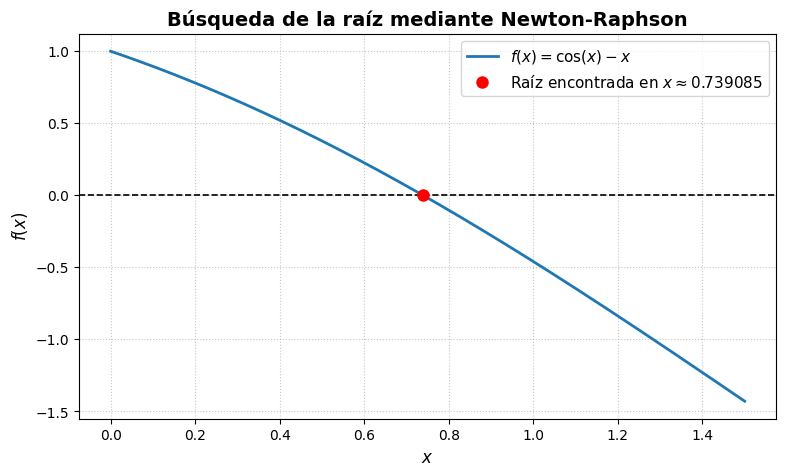

In [ ]:
x_vals = np.linspace(0, 1.5, 200)
y_vals = f(x_vals)

plt.figure(figsize=(9, 5))

# Gráfica de la función
plt.plot(x_vals, y_vals, label=r'$f(x) = \cos(x) - x$', color='#1f77b4', linewidth=2)

plt.axhline(0, color='black', linewidth=1.2, linestyle='--')

plt.plot(solucion_final, f(solucion_final), 'ro', markersize=8,
         label=f'Raíz encontrada en $x \\approx {solucion_final:.6f}$')

plt.title('Búsqueda de la raíz mediante Newton-Raphson', fontsize=14, fontweight='bold')
plt.xlabel('$x$', fontsize=12)
plt.ylabel('$f(x)$', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.7)

plt.show()